
% Class labels are: [0 1 2 3 4 5 6 7 8 9]
% Class frequencies are: (980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009)
class 1 = 5
class 2 = [9 8 0]


<ipython-input-6-81fa737aed76>:51: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  classone = np.in1d(labs,myDigit)
<ipython-input-6-81fa737aed76>:52: DeprecationWarning: `in1d` is deprecated. Use `np.isin` instead.
  classtwo = np.in1d(labs,others)


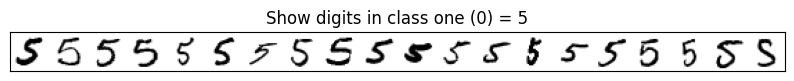

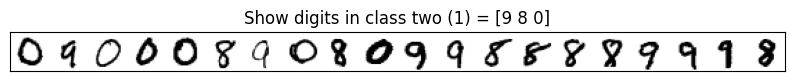

In [ ]:
import numpy as np

from time import time
import matplotlib.pyplot as plt
import scipy.io.matlab as matlab
from sklearn import datasets
from scipy.io import loadmat

from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDClassifier, Perceptron
from sklearn.neural_network import MLPClassifier


# Load the database
mat_file =  "BigDigits.mat"
mat = matlab.loadmat(mat_file,squeeze_me=True) # dictionary
list(mat.keys()) # list vars

taska = True

data = mat["data"]      # read feature vectors
labs = mat["labs"] - 1  # read labels 1..10

allNlabs = np.unique(labs) # all labs 0 .. 9

classsiz = ()
for c in allNlabs:
    classsiz = classsiz + (np.size(np.nonzero(labs==c)),)
print('\n%% Class labels are: %s' % (allNlabs,))
print('%% Class frequencies are: %s' % (classsiz,))


# Let's say my digit is ...
myDigit = 5

otherDigits  = np.setdiff1d(allNlabs,myDigit)
other3Digits = np.random.permutation(otherDigits)[:3]

if taska:
    others = other3Digits
else:
    others = otherDigits

print('class 1 = %s'%myDigit)
print('class 2 = %s' % others)

# To construct a 2-class dataset you can use the same matrix
# data and change the vector of labels

aux = labs
classone = np.in1d(labs,myDigit)
classtwo = np.in1d(labs,others)
aux[classone] = 0  # class one
aux[classtwo] = 1  # class two

# Features
X = data[np.logical_or(classone,classtwo)]
# (unchanged) labels
y = aux[np.logical_or(classone,classtwo)]


# Show some digits
hwmny = 20
some1 = np.random.permutation(np.where(y==0)[0])[:hwmny]
some2 = np.random.permutation(np.where(y==1)[0])[:hwmny]



img1 = np.reshape(X[some1,:],(28*hwmny,28)).T
plt.figure(figsize=(10,3))
plt.imshow(img1, cmap=plt.cm.gray_r)
plt.xticks([])
plt.yticks([])
plt.title('Show digits in class one (0) = '+str(myDigit) )
plt.show()


img2 = np.reshape(X[some2,:],(28*hwmny,28)).T
plt.figure(figsize=(10,3))
plt.imshow(img2, cmap=plt.cm.gray_r)
plt.xticks([])
plt.yticks([])
plt.title('Show digits in class two (1) = '+str(others) )
plt.show()



[[0.96, 0.9298043728423475, 0.9407114624505929, 0.9592169657422512, 0.9521690767519466], [0.9577777777777777, 0.9475446428571429, 0.9597826086956521, 0.9604072398190046, 0.9547738693467337], [0.961719979024646, 0.9647577092511013, 0.9566184649610678, 0.9203342618384401, 0.9550930996714129], [0.9688982604111755, 0.9427312775330396, 0.9566126502875065, 0.9677771709448388, 0.9636363636363636], [0.9653304442036836, 0.9398663697104677, 0.9648838465694219, 0.9457013574660633, 0.9512735326688815], [0.9688013136288999, 0.967067433350758, 0.9674319273892151, 0.9733759318423855, 0.9615170105967652]]


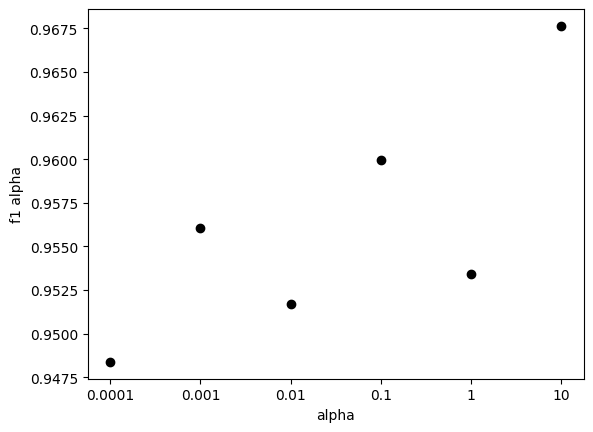

In [ ]:
#
#now we find the best parameters for SGD classifier
#

from sklearn.metrics import f1_score
seed = 42
rng = np.random.RandomState(seed)

rounds=5
#define hyperparameters for SGDClassifier tuning
alphas = ['0.0001', '0.001', '0.01', '0.1', '1', '10']
f1_alpha=[]
f1_mean=[]

#tune alpha parameter using average F1-score
for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
  model= SGDClassifier(loss='perceptron', alpha=alpha, eta0=1, learning_rate='constant', penalty=None)

  f1_rounds=[]
  sum=0
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)

    f1_rounds.append(f1_score(y_test, y_pred))

  f1_mean.append(sum/rounds)

  f1_alpha.append(f1_rounds)



print(f1_alpha)
plt.plot(f1_mean, "o", color="black")

plt.xlabel("alpha")
plt.ylabel("f1 alpha")
plt.xticks(np.arange(len(alphas)), [x for x in alphas])
plt.show()

#we have seen through the accuracy mean of every alpha value that the best alpha parameter is 0.1 so we use this value in the next steps


[[0.9628032345013477, 0.9666119321291735, 0.9601293103448276, 0.9606382978723405, 0.9547960308710033], [0.9672846237731734, 0.9581749049429658, 0.9676002196595277, 0.9581239530988275, 0.9656652360515021], [0.9587852494577006, 0.9572459744586341, 0.9660377358490566, 0.9641025641025641, 0.9618074233458849], [0.9619196661450182, 0.9516567083107007, 0.9697612732095491, 0.9673558215451578, 0.9611809732094041], [0.9659275283937263, 0.9567123287671233, 0.9665226781857451, 0.9607951408061844, 0.9575625680087051], [0.7716621253405994, 0.6551083591331269, 0.7213114754098361, 0.5790527018012008, 0.8590931253047294], [0.4483306836248013, 0.8236472945891784, 0.7397959183673469, 0.5075034106412005, 0.48552338530066813], [0.5093632958801498, 0.5994865211810013, 0.2873030583873957, 0.45901639344262296, 0.6548788474132285], [0.037460978147762745, 0.715915915915916, 0.15502392344497606, 0.5186226282501757, 0.1087866108786611]]


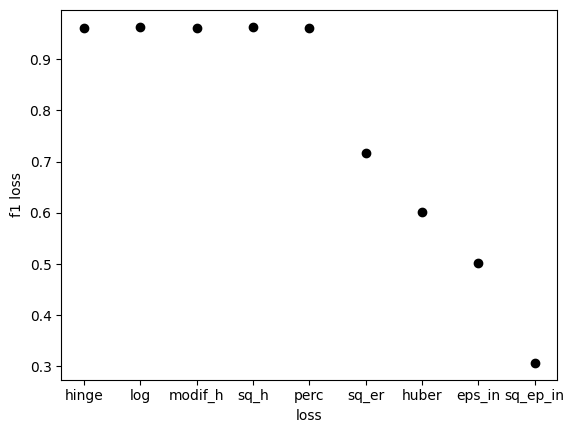

In [ ]:
from sklearn.metrics import f1_score
seed = 42
rng = np.random.RandomState(seed)

loss_functions = ['hinge', 'log', 'modif_h', 'sq_h', 'perc', 'sq_er', 'huber', 'eps_in', 'sq_ep_in']
f1_loss=[]
f1_loss_mean=[]

for loss in ['hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive']:
  model= SGDClassifier(loss=loss, alpha=0.1, eta0=1, learning_rate='constant', penalty=None)

  f1_rounds=[]
  sum=0;
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)
    f1_rounds.append(f1_score(y_test, y_pred))

  f1_loss_mean.append(sum/rounds)
  f1_loss.append(f1_rounds)

print(f1_loss)
plt.plot(f1_loss_mean, "o", color="black")

plt.xlabel("loss")
plt.ylabel("f1 loss")
plt.xticks(np.arange(len(loss_functions)), [x for x in loss_functions])
plt.show()

#we have seen through the accuracy mean of every loss value that the best loss parameter is perceptron so we use this value in the next steps

[[0.9645690111052353, 0.9656301145662848, 0.9481327800829875, 0.9721627408993576, 0.9604700854700855], [0.9657754010695188, 0.9594298245614035, 0.9385416666666667, 0.9631284916201117, 0.9558412520961431], [0.9627263045793397, 0.9646017699115044, 0.9702127659574468, 0.9742511823436679, 0.9655172413793104], [0.9433754810335349, 0.9325842696629213, 0.9701492537313433, 0.9532920652785594, 0.9401129943502825], [0.9681940700808626, 0.965771458662454, 0.9717333333333333, 0.9665753424657534, 0.9600886917960089], [0.9657387580299786, 0.9515058703420113, 0.926052332195677, 0.9738945125199787, 0.9726477024070022]]


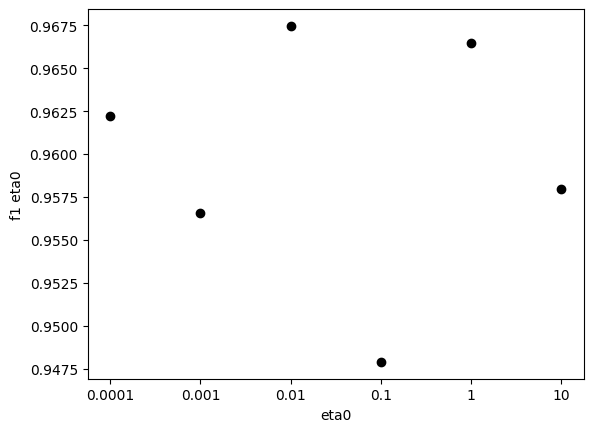

In [ ]:
from sklearn.metrics import f1_score
seed = 42
rng = np.random.RandomState(seed)

etas = [0.0001, 0.001, 0.01, 0.1, 1, 10]
f1_eta0=[]
f1_eta0_mean=[]

for eta0 in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
  model= SGDClassifier(loss='perceptron', alpha=0.1, eta0=eta0, learning_rate='constant', penalty='l1')

  f1_rounds=[]
  sum=0;
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)
    f1_rounds.append(f1_score(y_test, y_pred))

  f1_eta0_mean.append(sum/rounds)
  f1_eta0.append(f1_rounds)

print(f1_eta0)
plt.plot(f1_eta0_mean, "o", color="black")

plt.xlabel("eta0")
plt.ylabel("f1 eta0")
plt.xticks(np.arange(len(etas)), [x for x in etas])
plt.show()

#we have seen through the accuracy mean of every eta0 value that the best eta0 parameter is 0.001 so we use this value in the next steps

[[0.9649309245483528, 0.9428729894620078, 0.9563409563409564, 0.974120082815735, 0.9690937663698271], [0.9614147909967846, 0.9698924731182795, 0.9618798955613577, 0.9622030237580994, 0.9567147613762487], [0.9647058823529412, 0.9637912673056444, 0.9623156744948116, 0.9637760702524698, 0.9626943005181348], [0.9559139784946237, 0.9609856262833676, 0.9615795090715048, 0.9616837560712358, 0.9651100375738056]]


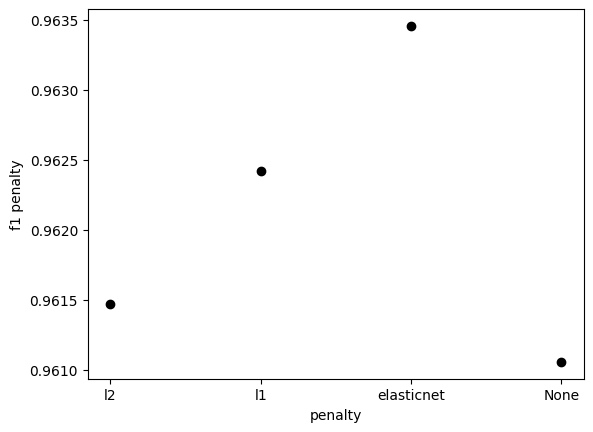

In [ ]:
from sklearn.metrics import f1_score
seed = 42
rng = np.random.RandomState(seed)

penalties = ['l2', 'l1', 'elasticnet', 'None']
f1_penalty=[]
f1_penalty_mean=[]

for penalty in ['l2', 'l1', 'elasticnet', None]:
  model= SGDClassifier(loss='perceptron', alpha=0.1, eta0=0.001, learning_rate='constant', penalty=penalty)

  f1_rounds=[]
  sum=0;
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)
    f1_rounds.append(f1_score(y_test, y_pred))

  f1_penalty_mean.append(sum/rounds)
  f1_penalty.append(f1_rounds)

print(f1_penalty)
plt.plot(f1_penalty_mean, "o", color="black")

plt.xlabel("penalty")
plt.ylabel("f1 penalty")
plt.xticks(np.arange(len(penalties)), [x for x in penalties])
plt.show()

#we have seen through the accuracy mean of every penalty value that the best penalty parameter is l1 so we use this value in the next steps

/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_stochastic

[[0.9716981132075472, 0.9664, 0.9249283667621776, 0.9524838012958964, 0.9685729005667182], [0.9556860651361452, 0.9597826086956521, 0.9635584137191854, 0.9516567083107007, 0.9575625680087051], [0.9543973941368078, 0.9503619441571872, 0.9536784741144414, 0.9536934950385888, 0.9632352941176471]]


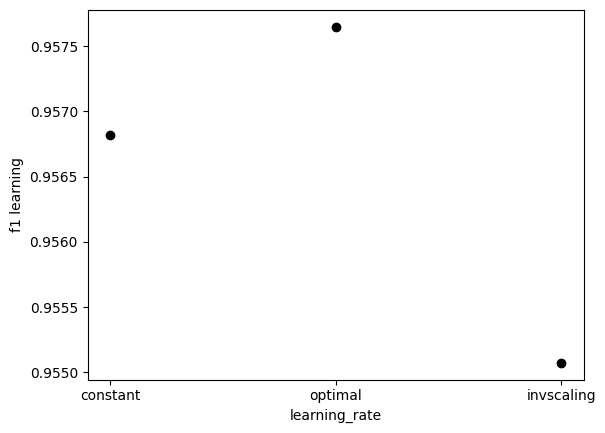

In [ ]:
from sklearn.metrics import f1_score
seed = 42
rng = np.random.RandomState(seed)

learnings = ['constant', 'optimal', 'invscaling']
f1_learning=[]
f1_learning_mean=[]

for learning_rate in ['constant', 'optimal', 'invscaling']:
  model= SGDClassifier(loss='perceptron', alpha=0.1, eta0=0.001, learning_rate=learning_rate, penalty='l1')

  f1_rounds=[]
  sum=0;
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)
    f1_rounds.append(f1_score(y_test, y_pred))

  f1_learning_mean.append(sum/rounds)
  f1_learning.append(f1_rounds)

print(f1_learning)
plt.plot(f1_learning_mean, "o", color="black")

plt.xlabel("learning_rate")
plt.ylabel("f1 learning")
plt.xticks(np.arange(len(learnings)), [x for x in learnings])
plt.show()

#we have seen trhough the accuracy mean of every learning_rate value that the best learning_rate parameter is 'constant'
#so the best parameters for SGDClassifiers are: loss='perceptron', alpha=0.1, eta0=0.001, learning_rate='constant', penalty='l1'.

[[0.9535951045385007, 0.9643605870020965, 0.9506037321624589, 0.9626068376068376, 0.9594017094017094], [0.9536842105263158, 0.9660010793308149, 0.9600415153087701, 0.9544264012572027, 0.9593852908891328], [0.9616797900262467, 0.9520255863539445, 0.9634801288936627, 0.9555677454744926, 0.956927867151012], [0.9582655826558265, 0.9602543720190779, 0.9547190398254228, 0.9538461538461539, 0.9645690111052353], [0.9387527839643652, 0.9657387580299786, 0.947795235681703, 0.9705573080967402, 0.9496248660235799], [0.9595119245701609, 0.96051227321238, 0.932806324110672, 0.9643806485911749, 0.9614775725593667]]


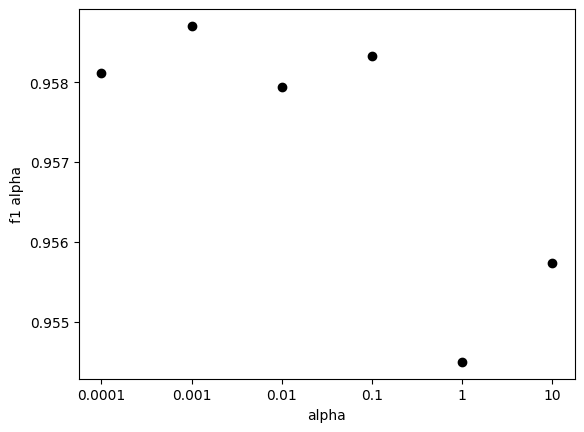

In [ ]:
#
#now we find the best parameters for Perceptron classifier
#

from sklearn.metrics import f1_score
seed = 42
rng = np.random.RandomState(seed)

rounds=5
alphas = ['0.0001', '0.001', '0.01', '0.1', '1', '10']
f1_alpha=[]
f1_mean=[]

for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
  model= Perceptron(alpha=alpha, tol=1e-5, eta0=1, penalty=None)

  f1_rounds=[]
  sum=0
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)

    f1_rounds.append(f1_score(y_test, y_pred))

  f1_mean.append(sum/rounds)

  f1_alpha.append(f1_rounds)



print(f1_alpha)
plt.plot(f1_mean, "o", color="black")

plt.xlabel("alpha")
plt.ylabel("f1 alpha")
plt.xticks(np.arange(len(alphas)), [x for x in alphas])
plt.show()

#we have seen through the accuracy mean of every alpha value that the best alpha parameter is 0.0001 so we use this value in the next steps


[[0.9605055292259084, 0.9584245076586433, 0.9697950377562028, 0.9633173843700159, 0.95995670995671], [0.9556048834628191, 0.9541577825159915, 0.9539325842696629, 0.9576031656302996, 0.9655172413793104], [0.9173363949483353, 0.960352422907489, 0.9643047416089504, 0.936569222283508, 0.9630818619582665], [0.9672219236969372, 0.9629629629629629, 0.9475308641975309, 0.9647577092511013, 0.9679173463839043], [0.961081081081081, 0.9653702717101759, 0.9621052631578947, 0.9613259668508287, 0.9590075512405609], [0.9717083786724701, 0.9670563230605739, 0.9621736814064997, 0.9661108122646584, 0.9650582362728786]]


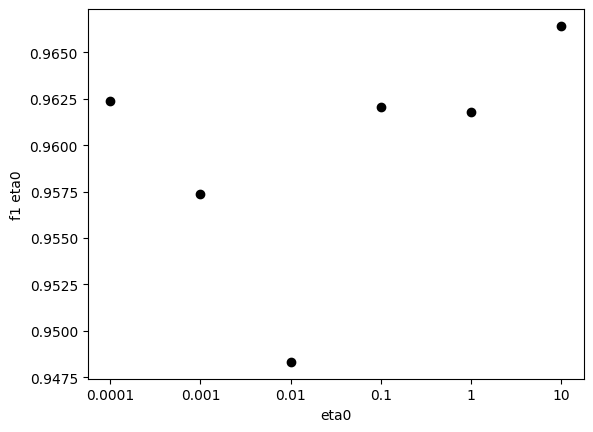

In [ ]:
from sklearn.metrics import f1_score
seed = 42
rng = np.random.RandomState(seed)

etas = [0.0001, 0.001, 0.01, 0.1, 1, 10]
f1_eta0=[]
f1_eta0_mean=[]

for eta0 in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
  model= Perceptron(alpha=0.0001, eta0=eta0, penalty=None)

  f1_rounds=[]
  sum=0;
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)
    f1_rounds.append(f1_score(y_test, y_pred))

  f1_eta0_mean.append(sum/rounds)
  f1_eta0.append(f1_rounds)

print(f1_eta0)
plt.plot(f1_eta0_mean, "o", color="black")

plt.xlabel("eta0")
plt.ylabel("f1 eta0")
plt.xticks(np.arange(len(etas)), [x for x in etas])
plt.show()

#we have seen through the accuracy mean of every eta0 value that the best eta0 parameter is 0.0001 so we use this value in the next steps

[[0.9535951045385007, 0.9643605870020965, 0.9506037321624589, 0.944078947368421, 0.9657676348547718], [0.9566596194503171, 0.9624387588459444, 0.9573770491803278, 0.9617834394904459, 0.9653304442036836], [0.9585798816568047, 0.9652220438737292, 0.9608879492600423, 0.9545454545454546, 0.9586864406779662], [0.9582655826558265, 0.9602543720190779, 0.9547190398254228, 0.9538461538461539, 0.9645690111052353]]


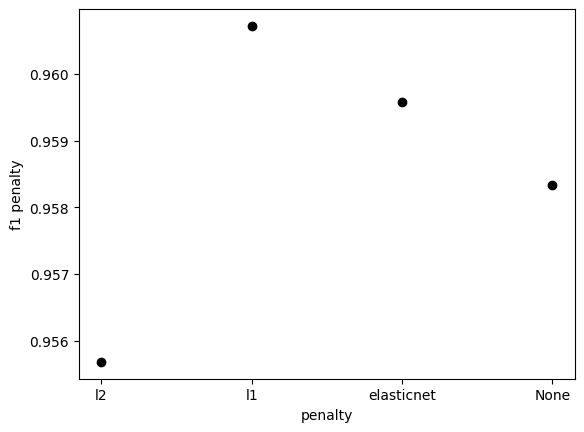

In [ ]:
from sklearn.metrics import f1_score
seed = 42
rng = np.random.RandomState(seed)

penalties = ['l2', 'l1', 'elasticnet', 'None']
f1_penalty=[]
f1_penalty_mean=[]

for penalty in ['l2', 'l1', 'elasticnet', None]:
  model= Perceptron(alpha=0.0001, tol=1e-5, eta0=0.0001, penalty=penalty)

  f1_rounds=[]
  sum=0;
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)
    f1_rounds.append(f1_score(y_test, y_pred))

  f1_penalty_mean.append(sum/rounds)
  f1_penalty.append(f1_rounds)

print(f1_penalty)
plt.plot(f1_penalty_mean, "o", color="black")

plt.xlabel("penalty")
plt.ylabel("f1 penalty")
plt.xticks(np.arange(len(penalties)), [x for x in penalties])
plt.show()

#we have seen through the accuracy mean of every penalty value that the best penalty parameter is None
#so the best parameters for Perceptron Classifier are alpha=0.0001, tol=1e-5, eta0=0.0001, penalty=None

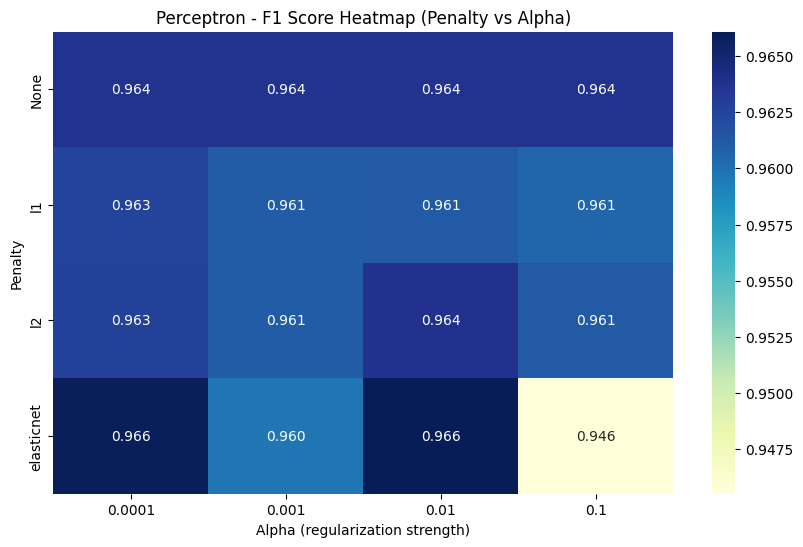

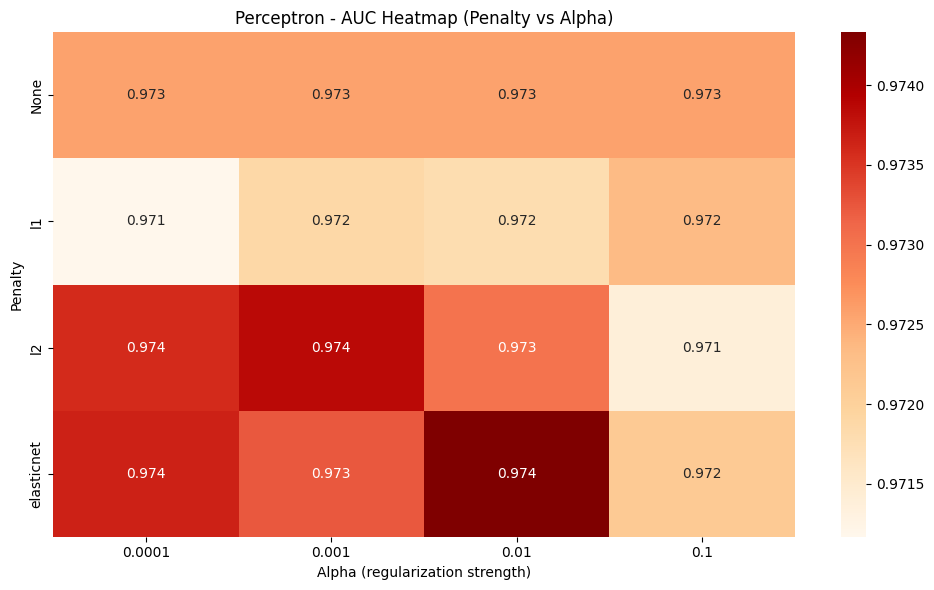

Best Perceptron config: penalty=elasticnet, alpha=0.01, eta0=0.001


In [ ]:
from sklearn.linear_model import Perceptron
from sklearn.metrics import f1_score, roc_curve, auc
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Parameters to test
penalties = [None, 'l1', 'l2', 'elasticnet']
alphas = [0.0001, 0.001, 0.01, 0.1]

f1_matrix = np.zeros((len(penalties), len(alphas)))
auc_matrix = np.zeros((len(penalties), len(alphas)))

eta0 = 0.001
rounds = 5
rng = 42
np.random.seed(rng)

for i, penalty in enumerate(penalties):
    for j, alpha in enumerate(alphas):
        f1_scores = []
        auc_scores = []
        for r in range(rounds):
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=r)
            try:
                model = Perceptron(penalty=penalty, alpha=alpha if penalty else 0.0, eta0=eta0, max_iter=300)
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)
                f1 = f1_score(y_test, y_pred)
                f1_scores.append(f1)

                if hasattr(model, "decision_function"):
                    y_scores = model.decision_function(X_test)
                else:
                    y_scores = model.predict_proba(X_test)[:, 1]  # fallback
                fpr, tpr, _ = roc_curve(y_test, y_scores)
                auc_score = auc(fpr, tpr)
                auc_scores.append(auc_score)
            except Exception as e:
                f1_scores.append(0)
                auc_scores.append(0)

        f1_matrix[i, j] = np.mean(f1_scores)
        auc_matrix[i, j] = np.mean(auc_scores)

# F1 heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(f1_matrix, annot=True, xticklabels=alphas, yticklabels=[str(p) for p in penalties], cmap="YlGnBu", fmt=".3f")
plt.xlabel("Alpha (regularization strength)")
plt.ylabel("Penalty")
plt.title("Perceptron - F1 Score Heatmap (Penalty vs Alpha)")
plt.show()

# AUC heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(auc_matrix, annot=True, xticklabels=alphas, yticklabels=[str(p) for p in penalties], cmap="OrRd", fmt=".3f")
plt.xlabel("Alpha (regularization strength)")
plt.ylabel("Penalty")
plt.title("Perceptron - AUC Heatmap (Penalty vs Alpha)")
plt.tight_layout()
plt.show()

# Best configuration
best_idx = np.unravel_index(np.argmax(f1_matrix), f1_matrix.shape)
best_penalty = penalties[best_idx[0]]
best_alpha = alphas[best_idx[1]]
print(f"Best Perceptron config: penalty={best_penalty}, alpha={best_alpha}, eta0={eta0}")


[[0.9836238774432118, 0.9867934495509773, 0.9823812066203951, 0.9899630216587427, 0.9878755930416447], [0.9850427350427351, 0.9837662337662337, 0.9892703862660944, 0.9837486457204767, 0.9831795984807379], [0.9850427350427351, 0.980203317281969, 0.9837310195227765, 0.9815217391304348, 0.9840595111583422], [0.9846322722283205, 0.9853709508881923, 0.9857670005271482, 0.9832522960561858, 0.9876939539860888], [0.9824561403508771, 0.9892008639308856, 0.986228813559322, 0.9894179894179894, 0.9840933191940615], [0.9745533297238765, 0.9684323167469235, 0.9778737182946573, 0.978494623655914, 0.9719428268925357]]


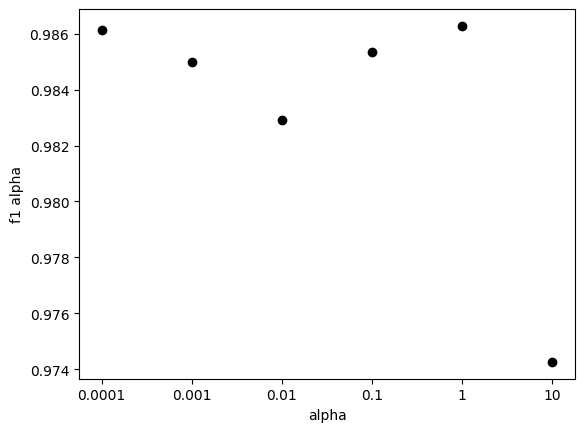

In [ ]:
#
#now we find the best parameters for MLP Classifier
#

from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler

seed = 42
rng = np.random.RandomState(seed)

rounds=5
alphas = ['0.0001', '0.001', '0.01', '0.1', '1', '10']
f1_alpha=[]
f1_mean=[]

#Input data is scaled, which is crucial for neural networks
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


for alpha in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
  model= MLPClassifier(hidden_layer_sizes=(30), max_iter=130, alpha=alpha, solver='sgd',tol=1e-4, learning_rate_init=.1)

  f1_rounds=[]
  sum=0
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X_scaled, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)

    f1_rounds.append(f1_score(y_test, y_pred))

  f1_mean.append(sum/rounds)

  f1_alpha.append(f1_rounds)



print(f1_alpha)
plt.plot(f1_mean, "o", color="black")

plt.xlabel("alpha")
plt.ylabel("f1 alpha")
plt.xticks(np.arange(len(alphas)), [x for x in alphas])
plt.show()

#we have seen through the accuracy mean of every alpha value that the best alpha parameter is 1 so we use this value in the next steps


[[0.9904661016949152, 0.9904761904761905, 0.985553772070626, 0.9920592906299629, 0.9905362776025236], [0.9856153436334576, 0.987027027027027, 0.9892933618843683, 0.9875338753387534, 0.9880952380952381], [0.9727748691099476, 0.960427807486631, 0.9679911699779249, 0.9716157205240175, 0.9751978891820581]]


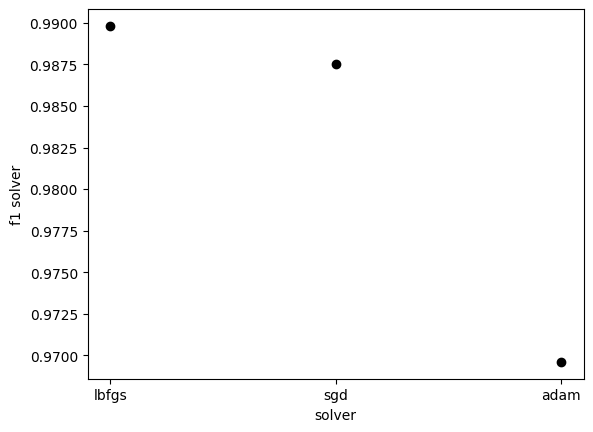

In [ ]:
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler

seed = 42
rng = np.random.RandomState(seed)

rounds=5
solvers = ['lbfgs', 'sgd', 'adam']
f1_solver=[]
f1_solver_mean=[]

#Input data is scaled, which is crucial for neural networks
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


for solver in ['lbfgs', 'sgd', 'adam']:
  model= MLPClassifier(hidden_layer_sizes=(30), alpha=1, solver=solver ,tol=1e-4, learning_rate_init=.1)

  f1_rounds=[]
  sum=0
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X_scaled, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)

    f1_rounds.append(f1_score(y_test, y_pred))

  f1_solver_mean.append(sum/rounds)

  f1_solver.append(f1_rounds)



print(f1_solver)
plt.plot(f1_solver_mean, "o", color="black")

plt.xlabel("solver")
plt.ylabel("f1 solver")
plt.xticks(np.arange(len(solvers)), [x for x in solvers])
plt.show()

#we have seen through the accuracy mean of every solver value that the best solver parameter is 'lbfgs' so we use this value in the next steps


[[0.9821525148729042, 0.9857456140350878, 0.9880823401950163, 0.9908944831280129, 0.9859002169197397], [0.9868995633187773, 0.9836244541484717, 0.9862561847168774, 0.9882220975883342, 0.9885683179096353], [0.9870967741935484, 0.9879912663755459, 0.9869565217391304, 0.9879391714735186, 0.9842476914720261], [0.9914802981895634, 0.986096256684492, 0.9903121636167922, 0.9890829694323144, 0.9881209503239741], [0.9891304347826086, 0.9913885898815931, 0.9908058409951325, 0.9891304347826086, 0.9917898193760263], [0.990185387131952, 0.9877854487519915, 0.9870828848223897, 0.9919657204070702, 0.987912087912088], [0.9874932028276238, 0.9911797133406836, 0.9900990099009901, 0.9882747068676717, 0.9881465517241379], [0.9841095890410959, 0.9892818863879957, 0.9856194690265486, 0.9906439185470556, 0.9874522640480087], [0.984930032292788, 0.9879385964912281, 0.9896907216494846, 0.9864712514092446, 0.9826330532212885], [0.9892125134843581, 0.9895085588072888, 0.9869848156182213, 0.9907457811649428, 0.98

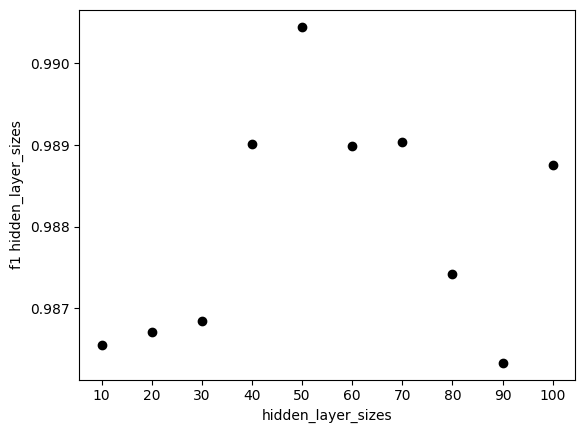

In [ ]:
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler

seed = 42
rng = np.random.RandomState(seed)

hiddens = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
f1_hidden=[]
f1_hidden_mean=[]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


for hidden_layer_sizes in [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]:
  model= MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, alpha=1, solver='lbfgs' , learning_rate_init=.1)

  f1_rounds=[]
  sum=0;
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X_scaled, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)
    f1_rounds.append(f1_score(y_test, y_pred))

  f1_hidden_mean.append(sum/rounds)
  f1_hidden.append(f1_rounds)

print(f1_hidden)
plt.plot(f1_hidden_mean, "o", color="black")

plt.xlabel("hidden_layer_sizes")
plt.ylabel("f1 hidden_layer_sizes")
plt.xticks(np.arange(len(hiddens)), [x for x in hiddens])
plt.show()

#we have seen through the accuracy mean of every hidden_layer_sizes value that the best hidden_layer_sizes parameter is 50

[[0.985945945945946, 0.9857612267250822, 0.9881465517241379, 0.9908847184986596, 0.9875338753387534], [0.9885433715220949, 0.9825517993456925, 0.9884297520661157, 0.9876543209876543, 0.9885558583106268], [0.9870828848223897, 0.9890470974808324, 0.989668297988037, 0.9916054564533053, 0.9853658536585366], [0.9909622541201488, 0.9860813704496788, 0.9913885898815931, 0.9901639344262295, 0.9875742841707186], [0.9880304678998912, 0.9913793103448276, 0.991887506760411, 0.9891540130151844, 0.9923329682365827], [0.990185387131952, 0.9893730074388948, 0.9865663621708759, 0.9914255091103966, 0.9900990099009901]]


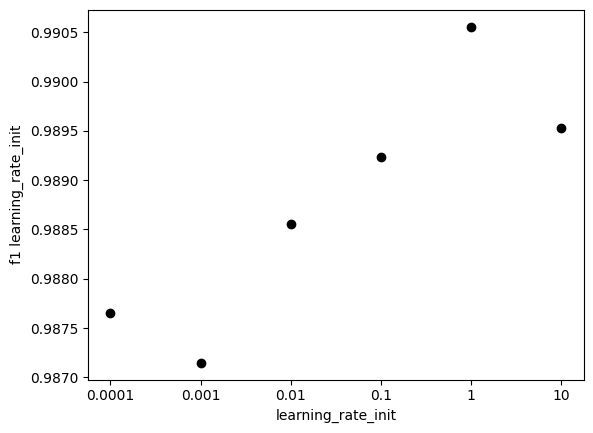

In [ ]:
from sklearn.metrics import f1_score
from sklearn.preprocessing import StandardScaler

seed = 42
rng = np.random.RandomState(seed)

# This parameter will not be used, because it is not used with lbfgs solver, which obtained the best result from all solvers.

learnings = [0.0001, 0.001, 0.01, 0.1, 1, 10]
f1_learning=[]
f1_learning_mean=[]

#Input data is scaled, which is crucial for neural networks
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for learning_rate_init in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
  model= MLPClassifier(hidden_layer_sizes=50, max_iter=130, alpha=1, solver='lbfgs' , learning_rate_init=learning_rate_init)

  f1_rounds=[]
  sum=0;
  for r in range(rounds):
    X_train, X_test, y_train, y_test = \
                        train_test_split(X_scaled, y, test_size=0.3, random_state=rng)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    sum+=f1_score(y_test, y_pred)
    f1_rounds.append(f1_score(y_test, y_pred))

  f1_learning_mean.append(sum/rounds)
  f1_learning.append(f1_rounds)

print(f1_learning)
plt.plot(f1_learning_mean, "o", color="black")

plt.xlabel("learning_rate_init")
plt.ylabel("f1 learning_rate_init")
plt.xticks(np.arange(len(learnings)), [x for x in learnings])
plt.show()

#we have seen through the accuracy mean of every learning_rate_init value that the best learning_rate_init parameter is 1
#so the best parameters for MPLClassifiers are: hidden_layer_sizes=(50), alpha=1, solver='lbfgs', learning_rate_init=1

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")
/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")
/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")
/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:698: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")
/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.11/d

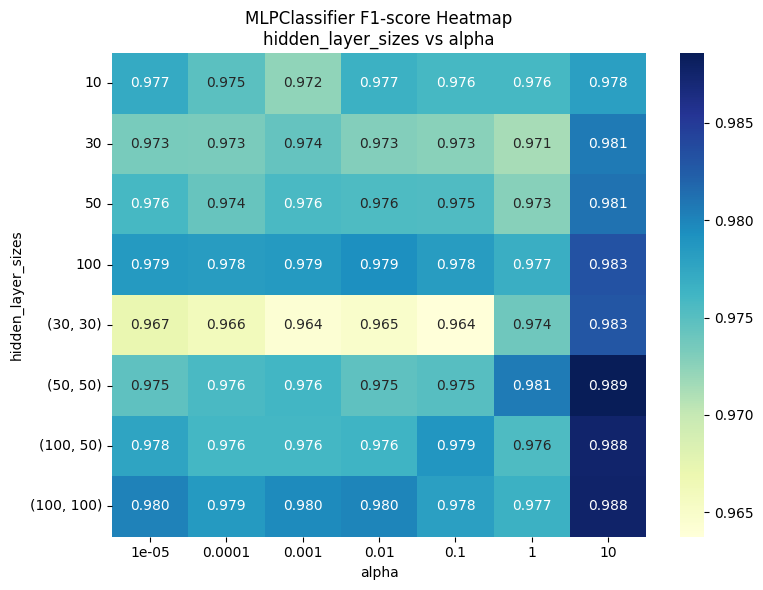

In [ ]:


# Now we will try to find the best configuration for the MLPClassifier. We will check following parameters: "hidden_layer_sizes", "alphas" and "learning_rates".
# The hidden_layer_sizes parameter responds to number of neurons in the ith hidden layer.

# Step 1: Compare two hyperparameters – hidden_layer_sizes and alpha
hidden_layer_sizes = [10, 30, 50, 100,(30,30), (50, 50), (100, 50), (100,100)]
alphas = [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1 , 10]
rounds = 3

results = []
for hls in hidden_layer_sizes:
    for alpha in alphas:
        f1_scores = []
        auc_scores = []
        for r in range(rounds):
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=r)
            clf = MLPClassifier(hidden_layer_sizes=hls, alpha=alpha, max_iter=200, random_state=0)
            clf.fit(X_train, y_train)
            # This time we will obtain two metrics, both f1_score and roc_auc_score
            y_pred = clf.predict(X_test)
            y_proba = clf.predict_proba(X_test)[:, 1]
            f1_scores.append(f1_score(y_test, y_pred))
            auc_scores.append(roc_auc_score(y_test, y_proba))
        results.append({
            "hidden_layer_sizes": hls,
            "alpha": alpha,
            "f1": np.mean(f1_scores),
            "roc_auc": np.mean(auc_scores)
        })

# Prepare heatmap data for plotting F1-scores
f1_matrix = np.zeros((len(hidden_layer_sizes), len(alphas)))
for i, hls in enumerate(hidden_layer_sizes):
    for j, alpha in enumerate(alphas):
        for res in results:
            if res["hidden_layer_sizes"] == hls and res["alpha"] == alpha:
                f1_matrix[i, j] = res["f1"]

f1_matrix, results  # Return both the heatmap matrix and raw results for further steps
f1_df = pd.DataFrame(
    f1_matrix,
    index=[str(h) for h in hidden_layer_sizes],
    columns=[str(a) for a in alphas]
)
plt.figure(figsize=(8, 6))
sns.heatmap(f1_df, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("MLPClassifier F1-score Heatmap\nhidden_layer_sizes vs alpha")
plt.xlabel("alpha")
plt.ylabel("hidden_layer_sizes")
plt.tight_layout()
plt.show()

# Now we can access and obtain the best configuration from the heatmap

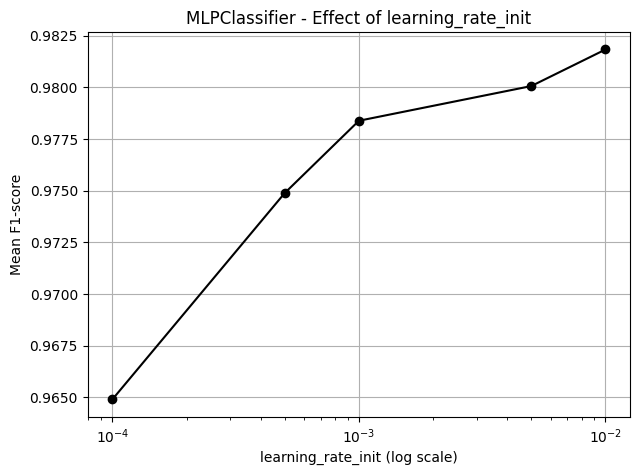

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, roc_auc_score
from scipy.io import loadmat


# Best settings after step 1:
best_hidden_layer_sizes = (50,50)
best_alpha = 10

# In step 2 we will compare diffrent  learning_rates with fixed parameters from the previous step.
learning_rates = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]
rounds = 3

lr_f1_scores = []
lr_auc_scores = []

for lr in learning_rates:
    f1s = []
    aucs = []
    for r in range(rounds):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=r)
        clf = MLPClassifier(hidden_layer_sizes=best_hidden_layer_sizes,alpha=best_alpha,
            learning_rate_init=lr,max_iter=200,random_state=0)
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_proba = clf.predict_proba(X_test)[:, 1]
        f1s.append(f1_score(y_test, y_pred))
        aucs.append(roc_auc_score(y_test, y_proba))
    lr_f1_scores.append(np.mean(f1s))
    lr_auc_scores.append(np.mean(aucs))

# Plot F1-score vs learning_rate_init
plt.figure(figsize=(7, 5))
plt.plot(learning_rates, lr_f1_scores, marker='o', color='black')
plt.xscale('log')
plt.xlabel("learning_rate_init (log scale)")
plt.ylabel("F1-score")
plt.title("MLPClassifier - Effect of learning_rate_init")
plt.grid(True)
plt.show()


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

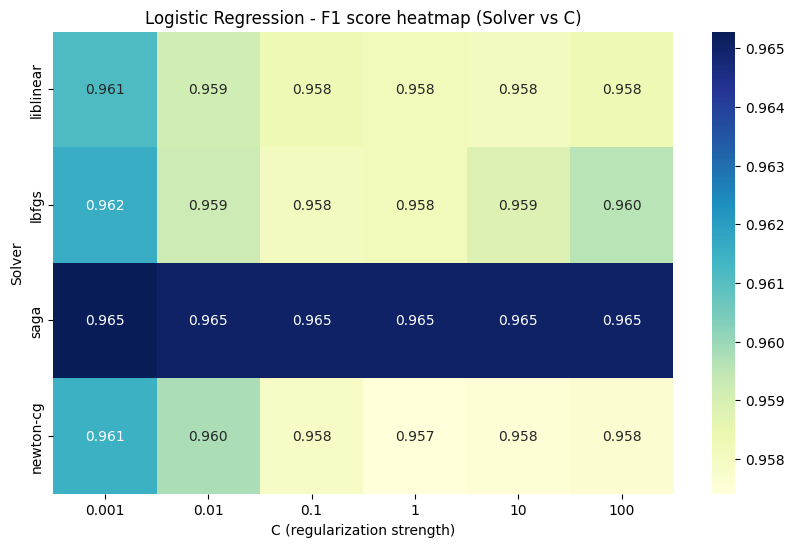

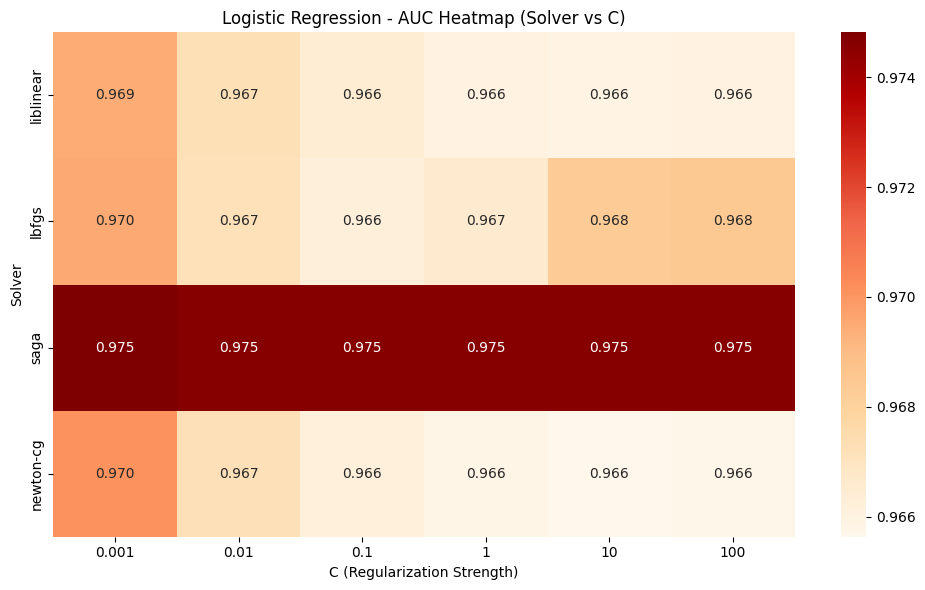

Best solver: saga, best C: 0.001


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
import seaborn as sns

# Now we will try to find the best possible parameters for LogisticRegression classifier. In order to do that we chose: "C", "solver" and "penalty" as the most
# important parameters which have the biggest influence on the results. Solver responds to the algorithm used in order to compute the problem, C controls the inverse of regularization strength.
# It is responsible for controlling of overfitting, the smaller C the stronger regularization, which prevents overfitting by shrinking coefficients more. The larger C the weaker regularization,
# which leads to closer training but the risk of overfitting is higher. Penalty as well as C responds to regularization. It specifies the type of regularization applied to prevent overfitting.


# In the first step we will compare diffrent solvers and Cs to see which combination makes the classifier the most efficient.

# Parameters
solvers = ['liblinear', 'lbfgs', 'saga', 'newton-cg']
Cs = [0.001, 0.01, 0.1, 1, 10, 100]

f1_matrix = np.zeros((len(solvers), len(Cs)))
auc_matrix = np.zeros((len(solvers), len(Cs)))


# Other data
rounds = 5  # number or rounds to average the score
rng = 42    # seed
np.random.seed(rng)

for i, solver in enumerate(solvers):
    for j, C in enumerate(Cs):
        f1_scores = []
        auc_scores = []
        for r in range(rounds):
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=r)
            try:
                model = LogisticRegression(solver=solver, C=C, penalty='l2', max_iter=500)
                model.fit(X_train, y_train)
                y_pred = model.predict(X_test)
                f1 = f1_score(y_test, y_pred)
                f1_scores.append(f1)
                if hasattr(model, "decision_function"):
                    y_scores = model.decision_function(X_test)
                else:
                    y_scores = model.predict_proba(X_test)[:, 1]

                fpr, tpr, _ = roc_curve(y_test, y_scores)
                auc_score = auc(fpr, tpr)
                auc_scores.append(auc_score)
            except:
                f1_scores.append(0)
                auc_scores.append(0)  # invalid parameters (if applicable)
        f1_matrix[i, j] = np.mean(f1_scores)
        auc_matrix[i, j] = np.mean(auc_scores)

# Heatmap f1_score
plt.figure(figsize=(10, 6))
sns.heatmap(f1_matrix, annot=True, xticklabels=Cs, yticklabels=solvers, cmap="YlGnBu", fmt=".3f")
plt.xlabel("C (regularization strength)")
plt.ylabel("Solver")
plt.title("Logistic Regression - F1 score heatmap (Solver vs C)")
plt.show()


# Heatmap AUC
plt.figure(figsize=(10, 6))
sns.heatmap(auc_matrix, annot=True, xticklabels=Cs, yticklabels=solvers, cmap="OrRd", fmt=".3f")
plt.xlabel("C (Regularization Strength)")
plt.ylabel("Solver")
plt.title("Logistic Regression - AUC Heatmap (Solver vs C)")
plt.tight_layout()
plt.show()

# Best parameters obtain after this step
best_idx = np.unravel_index(np.argmax(f1_matrix), f1_matrix.shape)
best_solver = solvers[best_idx[0]]
best_C = Cs[best_idx[1]]
print(f"Best solver: {best_solver}, best C: {best_C}")


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef

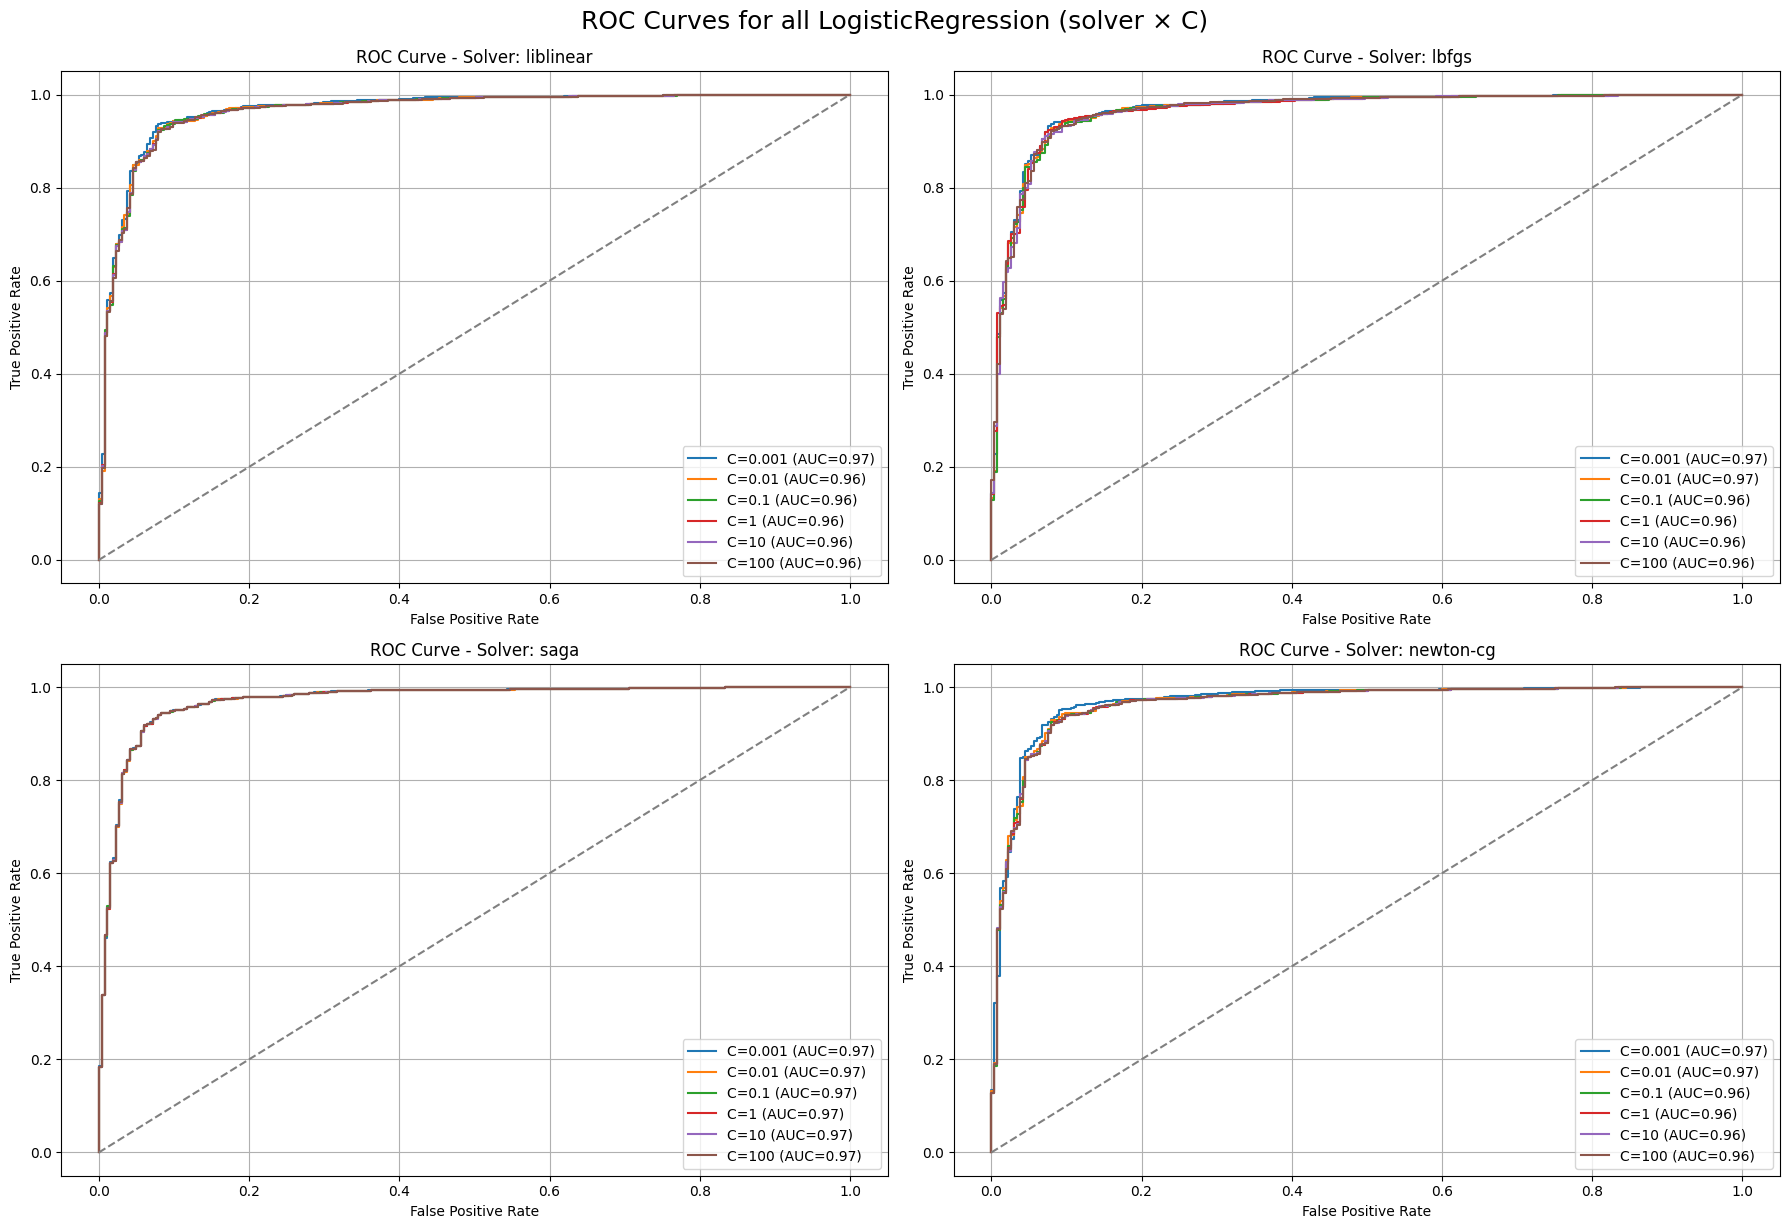

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

# This part will provide us additional results of roc_curve performance and will plot graphs for each of the solvers with all possible Cs.

solvers = ['liblinear', 'lbfgs', 'saga', 'newton-cg']
Cs = [0.001, 0.01, 0.1, 1, 10, 100]

rng = 42
np.random.seed(rng)

plt.figure(figsize=(18, 12))

for i, solver in enumerate(solvers):
    plt.subplot(2, 2, i + 1)
    success = False  # flag for at least one working model
    for C in Cs:
        try:
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

            # Ensure both classes are in y_train (added because of an error encountered)
            if len(np.unique(y_train)) < 2:
                raise ValueError("Only one class in training set")

            model = LogisticRegression(solver=solver, C=C, penalty='l2', max_iter=500)
            model.fit(X_train, y_train)

            if hasattr(model, "decision_function"):
                y_scores = model.decision_function(X_test)
            else:
                y_scores = model.predict_proba(X_test)[:, 1]

            fpr, tpr, _ = roc_curve(y_test, y_scores)
            auc_score = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f'C={C} (AUC={auc_score:.2f})')
            success = True

        except Exception as e:
            print(f"Error for solver={solver}, C={C} → {str(e)}")

    if success:
        plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
        plt.title(f"ROC Curve - Solver: {solver}")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.legend()
        plt.grid(True)
    else:
        plt.text(0.5, 0.5, "No valid results", ha='center', va='center', fontsize=12)

plt.tight_layout()
plt.suptitle("ROC Curves for all LogisticRegression (solver × C)", fontsize=18, y=1.02)
plt.show()


/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Penalty: l1, F1-score: 0.9698
Penalty: l2, F1-score: 0.9696
Penalty: None, F1-score: 0.9696
Best (penalty): l1


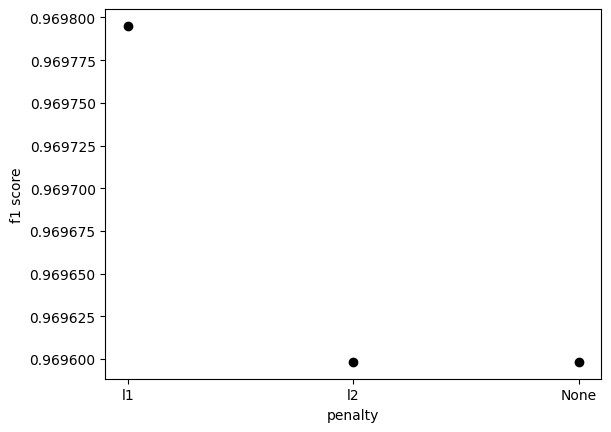

In [ ]:

# Now in the second step we will try to choose the best penalty for already choosen parameters from the first step.

penalties = ['l1', 'l2', None]
penalties_names = ['l1', 'l2', "None"]
f1_penalties = []

for penalty in penalties:
    f1_scores = []
    for r in range(rounds):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=r)
        try:
            # If everything is fine the model is trained then the prediction is made and f1score is obtain and added to the list
            # If not we insert value 0 to the list
            model = LogisticRegression(solver=best_solver, C=best_C, penalty=penalty, max_iter=200)
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            f1 = f1_score(y_test, y_pred)
            f1_scores.append(f1)
        except:
            f1_scores.append(0)
    # After all rounds the mean of scores is computed for a specific classifier and added to the final result
    f1_penalties.append(np.mean(f1_scores))

# Presentation of the results in the table
for p, score in zip(penalties, f1_penalties):
    print(f"Penalty: {p}, F1-score: {score:.4f}")

best_penalty = penalties[np.argmax(f1_penalties)]
print(f"Best (penalty): {best_penalty}")

# In order to present the results we create a simple plot

plt.plot(f1_penalties, "o", color="black")
plt.xlabel("penalty")
plt.ylabel("f1 score")
plt.xticks(np.arange(len(penalties_names)), [x for x in penalties_names])
plt.show()


# After these two steps we achive the best combination of the parameters for LogisticRegression classifier, which will be later
# compared to the other classifiers. The best configuration:  LogisticRegression(solver = saga, C = 0.001, penalty = l1, max_iter=500)


Solver:    svd, F1-score: 0.9590, ROC AUC: 0.9494
Solver:   lsqr, F1-score: 0.9696, ROC AUC: 0.9733
Solver:  eigen, F1-score: 0.9696, ROC AUC: 0.9733


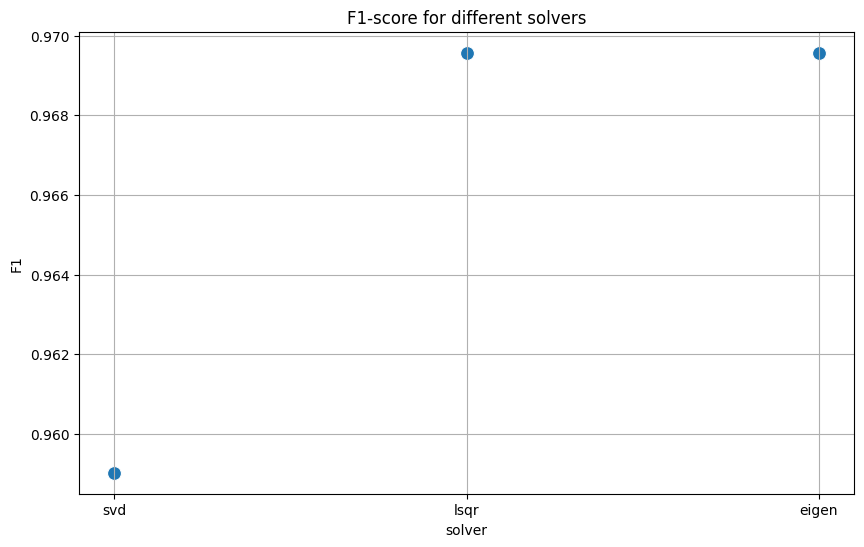

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_auc_score
import pandas as pd
import seaborn as sns


# In this section we will try to obtain the best LinearDiscriminantAnalysis. In order to do that we will test the "solver" parameter.
# Solver is as always responsible for the type of algorithm used in the classifier.

solvers = ['svd', 'lsqr', 'eigen']
rounds = 5

results = []
for solver in solvers:
    f1_scores = []
    auc_scores = []
    for r in range(rounds):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=r)
        try:
            if solver == 'svd':
                clf = LinearDiscriminantAnalysis(solver=solver)
            else:
                clf = LinearDiscriminantAnalysis(solver=solver, shrinkage='auto')
            clf.fit(X_train, y_train)
            y_pred = clf.predict(X_test)
            y_proba = clf.predict_proba(X_test)[:, 1]
            f1_scores.append(f1_score(y_test, y_pred))
            auc_scores.append(roc_auc_score(y_test, y_proba))
        except Exception as e:
            f1_scores.append(0)
            auc_scores.append(0)
    results.append({
        'solver': solver,
        'F1': np.mean(f1_scores),
        'ROC AUC': np.mean(auc_scores)
    })

# Presentation of the results
for res in results:
    print(f"Solver: {res['solver']:>6}, "
          f"F1-score: {res['F1']:.4f}, ROC AUC: {res['ROC AUC']:.4f}")


df = pd.DataFrame(results)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='solver', y='F1', s=100)
plt.title("F1-score for different solvers")
plt.grid(True)
plt.show()


# The plot and results shows that both solvers eigen and lsqr with auto shrinkage were the best and finished with the same scores. For our testing we will choose eigen solver.
# The best configuration: LinearDiscriminantAnalysis(solver='eigen', shrinkage = 'auto')

/usr/local/lib/python3.11/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

QDA average F1-score over 5 runs: 0.8798


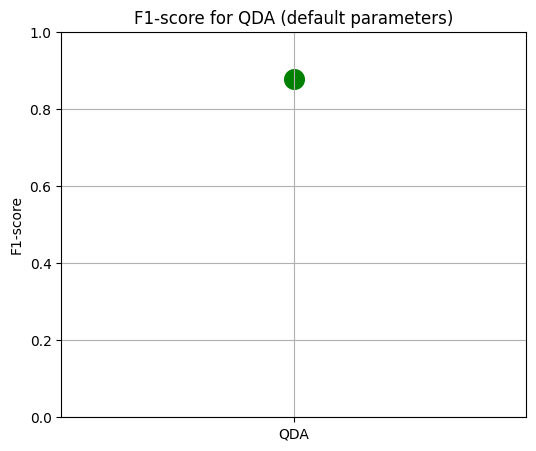

In [ ]:

# In this section we will compute QuadraticDiscriminantAnalysis classifier. Because it does not have any particulary important parapeters we will use the default settings.

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt
import numpy as np

qda = QuadraticDiscriminantAnalysis()
rounds = 5
f1_scores = []

# We will measure the performence 5 times in order to obtain the most reliable scores
for r in range(rounds):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=r)
    try:
        qda.fit(X_train, y_train)
        y_pred = qda.predict(X_test)
        f1 = f1_score(y_test, y_pred)
        f1_scores.append(f1)
    except Exception as e:
        print(f"QDA failed in round {r}: {e}")
        f1_scores.append(0)

# Mean F1-score
avg_f1_qda = np.mean(f1_scores)
print(f"QDA average F1-score over {rounds} runs: {avg_f1_qda:.4f}")

# Plot for F1-score (one point)
plt.figure(figsize=(6, 5))
plt.scatter(['QDA'], [avg_f1_qda], color='green', s=200)
plt.title("F1-score for QDA (default parameters)")
plt.ylabel("F1-score")
plt.ylim(0, 1)
plt.grid(True)
plt.show()




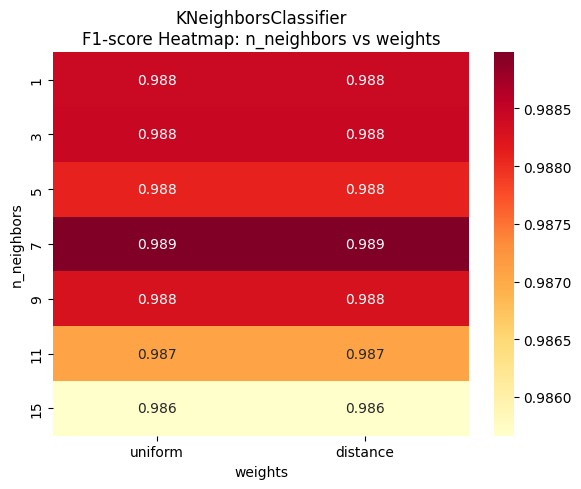

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
import seaborn as sns
import pandas as pd


# Now we will find the best configuration for the KNeighborsClassifier using following parameters: "n_neighbors", "weights" and "metric".
# Parameter n_neighbors chooses how many neighbors will be taken into acount while computing the result. Weights is responsible for adjusting the
# weight, "importance" of the points in the neighborhood and metric parameter chooses the way in which the distance is computed.


# First parameters to compare
neighbors_range = [1, 3, 5, 7, 9, 11, 15]
weights_options = ['uniform', 'distance']
rounds = 3

f1_matrix = np.zeros((len(neighbors_range), len(weights_options)))

# For each combination of parameters (for each combination three times to obtain reliable results) we split, train and get f1_score
# then we save the results in the temporary table and after computing 3-times we calculate the mean of scores.
for i, k in enumerate(neighbors_range):
    for j, w in enumerate(weights_options):
        f1_scores = []
        for r in range(rounds):
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=r)
            clf = KNeighborsClassifier(n_neighbors=k, weights=w)
            clf.fit(X_train, y_train)
            y_pred = clf.predict(X_test)
            f1_scores.append(f1_score(y_test, y_pred))
        f1_matrix[i, j] = np.mean(f1_scores)

# Heatmap of obtained scores
f1_df = pd.DataFrame(
    f1_matrix,
    index=[str(k) for k in neighbors_range],
    columns=weights_options
)

plt.figure(figsize=(6, 5))
sns.heatmap(f1_df, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("KNeighborsClassifier\nF1-score Heatmap: n_neighbors vs weights")
plt.xlabel("weights")
plt.ylabel("n_neighbors")
plt.tight_layout()
plt.show()


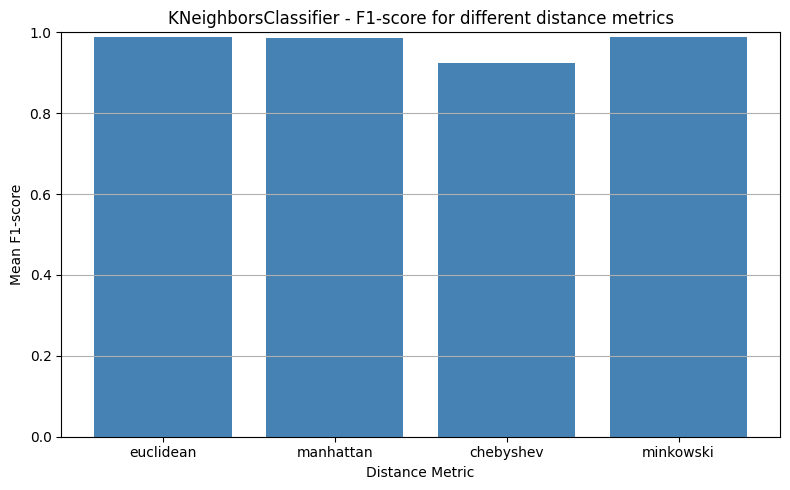

In [ ]:
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

# The best parameters received after the first step:
best_k = 7
best_weights = 'uniform'

# Metrics to compare in the second step:
metrics = ['euclidean', 'manhattan', 'chebyshev', 'minkowski']
rounds = 3

f1_scores = []
roc_auc_scores = []

for metric in metrics:
    f1s = []
    aucs = []
    for r in range(rounds):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=r)
        clf = KNeighborsClassifier(n_neighbors=best_k, weights=best_weights, metric=metric)
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_proba = clf.predict_proba(X_test)[:, 1]
        f1s.append(f1_score(y_test, y_pred))
        aucs.append(roc_auc_score(y_test, y_proba))
    f1_scores.append(np.mean(f1s))
    roc_auc_scores.append(np.mean(aucs))

# F1_score plot, presenting the results
plt.figure(figsize=(8, 5))
plt.bar(metrics, f1_scores, color='steelblue')
plt.title("KNeighborsClassifier - F1-score for different distance metrics")
plt.ylabel("Mean F1-score")
plt.xlabel("Distance Metric")
plt.ylim(0, 1)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

# From the plot we can read that the best metric is Minkowski, which is used as the default one. However every metric apart form chebyshev performs really well.

# Therefore the best combination of parameters for KNeighborsClassifier is: KNeighborsClassifier(n_neighbors = 7 , weights = "uniform", metric= "minkowski")

/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.11/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL: .

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_sag.py:348:

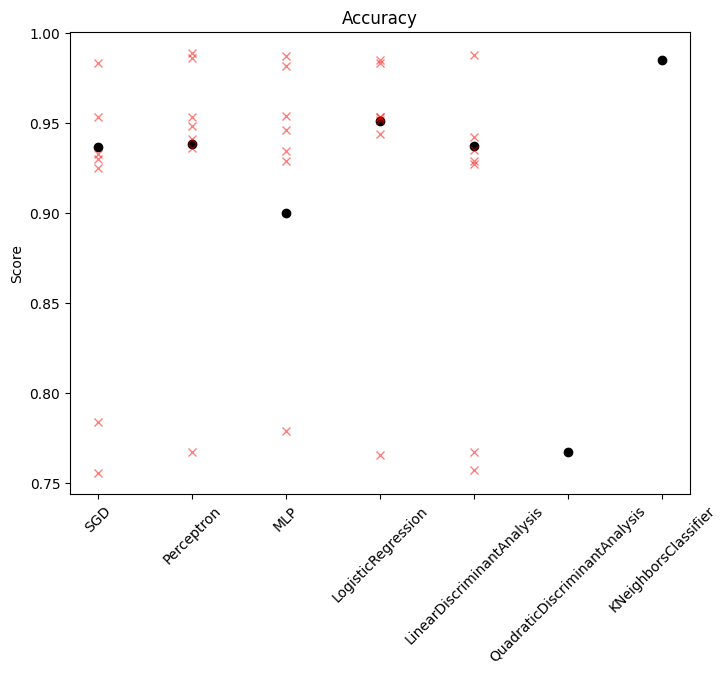

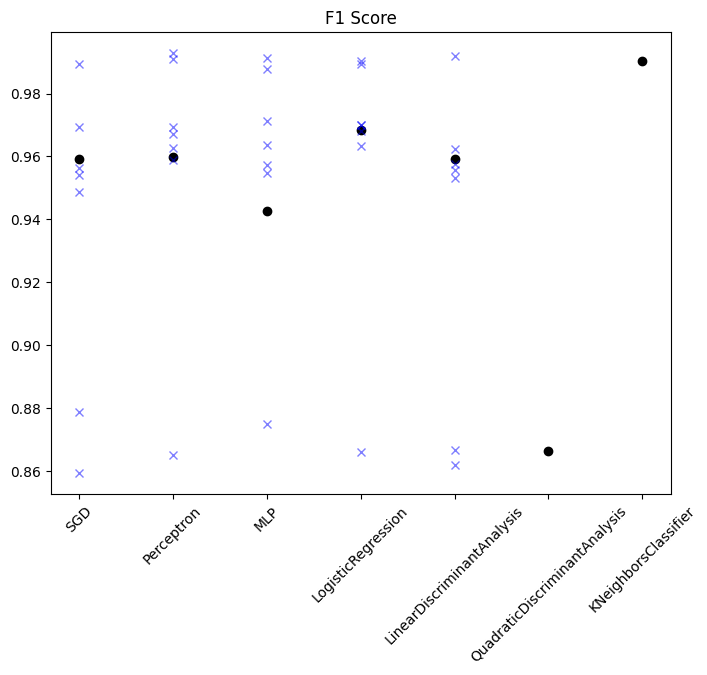

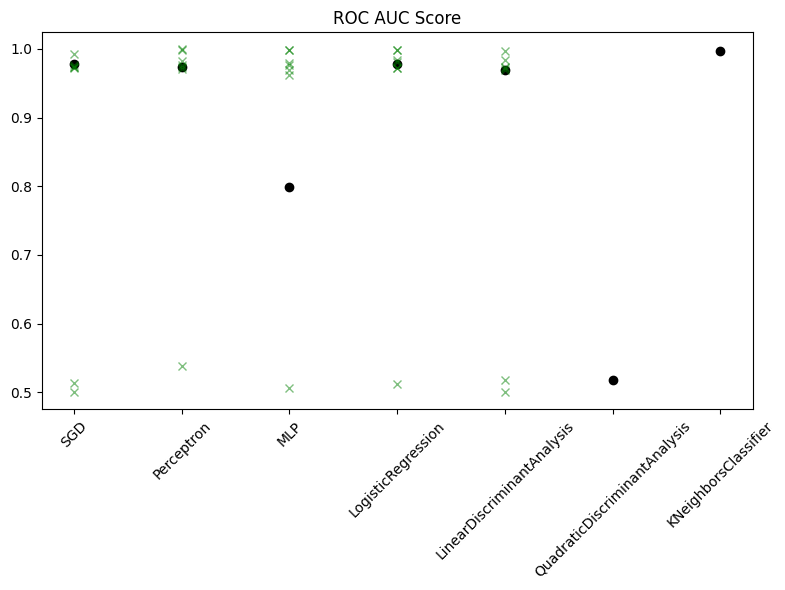

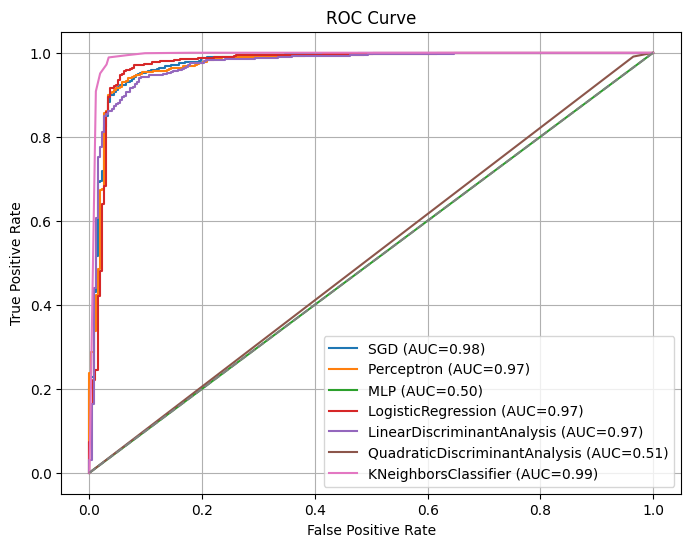

In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np

# In the last part we will compare all classifiers where each of them is in its best configuration. The goal of this comparison is to find the best and most efficient
# classifier for our problem, which is to distinguish our number (5) from the others (digits recognition).

seed = 42
rng = np.random.RandomState(seed)

classifiers = [
    ("SGD", SGDClassifier(loss='perceptron',alpha=0.1, eta0=0.001, learning_rate='constant', penalty='l1')),
    ("Perceptron",Perceptron(alpha=0.0001, eta0=0.0001, penalty=None)),
    ("MLP",MLPClassifier(hidden_layer_sizes=(50,50), max_iter=500, alpha=10, solver='lbfgs')),
    ("LogisticRegression",LogisticRegression(solver = 'saga', C = 0.001, penalty = 'l1', max_iter=500)),
    ("LinearDiscriminantAnalysis",LinearDiscriminantAnalysis(solver = "eigen", shrinkage = "auto")),
    ("QuadraticDiscriminantAnalysis",QuadraticDiscriminantAnalysis()),
    ("KNeighborsClassifier",KNeighborsClassifier(n_neighbors = 7 , weights = "uniform", metric= "minkowski"))
]

# Lists for the results: accuracy, f1_score, auc_score and roc_curves
acc_models = []
f1_models = []
auc_models = []
roc_curves = []

# For the better, balanced results we will do it 5 times
rounds = 5

# For each classifier we will measure all metrics in order to choose the best classifier.
for name, model in classifiers:
    acc_rounds = []
    f1_rounds = []
    auc_rounds = []

    for r in range(rounds):

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=rng)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        acc = model.score(X_test, y_test)
        acc_rounds.append(acc)

        f1 = f1_score(y_test, y_pred)
        f1_rounds.append(f1)

        # Checking if model has predict_proba
        try:
            y_score = model.predict_proba(X_test)[:, 1]
        except:
            # If not we use decision_function
            try:
                y_score = model.decision_function(X_test)
            except:
                y_score = None
        if y_score is not None:
            fpr, tpr, _ = roc_curve(y_test, y_score)
            auc_val = roc_auc_score(y_test, y_score)
            if r == 0:  # We will save the roc_curve only from the first round
                roc_curves.append((name, fpr, tpr, auc_val))
            auc_rounds.append(auc_val)
        else:
            auc_rounds.append(np.nan)
            if r == 0:
                roc_curves.append((name, None, None, None))

    acc_models.append(acc_rounds)
    f1_models.append(f1_rounds)
    auc_models.append(auc_rounds)

acc_models = np.array(acc_models)
f1_models = np.array(f1_models)
auc_models = np.array(auc_models)

# Compute the mean
average_acc = np.mean(acc_models, axis=1)
average_f1 = np.mean(f1_models, axis=1)
average_auc = np.nanmean(auc_models, axis=1)

# Accuracy plot
plt.figure(figsize=(8, 6))
plt.plot(average_acc, "o", color="black")
plt.plot(acc_models.T, "x", color="red", alpha=0.5)
plt.title("Accuracy")
plt.xticks(np.arange(len(classifiers)), [x[0] for x in classifiers], rotation=45)
plt.ylabel("Score")

# F1_score plot
plt.figure(figsize=(8, 6))
plt.plot(average_f1, "o", color="black")
plt.plot(f1_models.T, "x", color="blue", alpha=0.5)
plt.title("F1 Score")
plt.xticks(np.arange(len(classifiers)), [x[0] for x in classifiers], rotation=45)

# Auc plot
plt.figure(figsize=(8, 6))
plt.plot(average_auc, "o", color="black")
plt.plot(auc_models.T, "x", color="green", alpha=0.5)
plt.title("ROC AUC Score")
plt.xticks(np.arange(len(classifiers)), [x[0] for x in classifiers], rotation=45)

plt.tight_layout()
plt.show()

# Plot for all roc_curves
plt.figure(figsize=(8, 6))
for name, fpr, tpr, auc_val in roc_curves:
    if fpr is not None:
        plt.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
print(average_acc)
print(average_f1)
print(average_auc)

NameError: name 'average_acc' is not defined